In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:


df = pd.read_csv(
    "/content/DataCoSupplyChainDataset.csv",
    encoding="latin1"
)

In [10]:
df.shape

(180519, 53)

## Data Cleaning

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [19]:
df.rename(columns={
    'Type': 'order_type',
    'Days for shipping (real)': 'actual_shipping_days',
    'Days for shipment (scheduled)': 'scheduled_shipping_days',
    'Benefit per order': 'benefit_per_order',
    'Sales per customer': 'sales_per_customer',
    'Delivery Status': 'delivery_status',
    'Late_delivery_risk': 'late_delivery_risk',
    'Category Name': 'category_name',
    'Customer City': 'customer_city',
    'Customer Country': 'customer_country',
    'Customer Id': 'customer_id',
    'Customer Segment': 'customer_segment',
    'Department Name': 'department_name',
    'Market': 'market',
    'Order City': 'order_city',
    'Order Country': 'order_country',
    'order date (DateOrders)': 'order_date',
    'Order Id': 'order_id',
    'Order Item Discount': 'order_discount',
    'Order Item Quantity': 'order_quantity',
    'Sales': 'sales',
    'Order Item Total': 'order_total',
    'Order Profit Per Order': 'order_profit',
    'Product Name': 'product_name',
    'Shipping Mode': 'shipping_mode'
}, inplace=True)


In [21]:
columns = [
    'order_type', 'actual_shipping_days', 'scheduled_shipping_days', 'benefit_per_order',
    'sales_per_customer', 'delivery_status', 'late_delivery_risk', 'category_name',
    'customer_city', 'customer_country', 'customer_id', 'customer_segment',
    'department_name', 'market', 'order_city', 'order_country', 'order_date',
    'order_id', 'order_discount', 'order_quantity', 'sales', 'order_total',
    'order_profit', 'product_name', 'shipping_mode'
]

df_25 = df[columns]
df_25.head()

,order_type,actual_shipping_days,scheduled_shipping_days,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_name,customer_city,customer_country,...,order_country,order_date,order_id,order_discount,order_quantity,sales,order_total,order_profit,product_name,shipping_mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,Indonesia,1/31/2018 22:56,77202,13.110000,1,327.75,314.640015,91.250000,Smart watch,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,India,1/13/2018 12:27,75939,16.389999,1,327.75,311.359985,-249.089996,Smart watch,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,India,1/13/2018 12:06,75938,18.030001,1,327.75,309.720001,-247.779999,Smart watch,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,Australia,1/13/2018 11:45,75937,22.940001,1,327.75,304.809998,22.860001,Smart watch,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,Australia,1/13/2018 11:24,75936,29.500000,1,327.75,298.250000,134.210007,Smart watch,Standard Class


In [22]:
df_25.shape

(180519, 25)

In [23]:

df_25.columns


Index(['order_type', 'actual_shipping_days', 'scheduled_shipping_days',
       'benefit_per_order', 'sales_per_customer', 'delivery_status',
       'late_delivery_risk', 'category_name', 'customer_city',
       'customer_country', 'customer_id', 'customer_segment',
       'department_name', 'market', 'order_city', 'order_country',
       'order_date', 'order_id', 'order_discount', 'order_quantity', 'sales',
       'order_total', 'order_profit', 'product_name', 'shipping_mode'],
      dtype='object')

In [24]:

df_25 = df_25.dropna()

In [25]:
df_25["order_id"] = df_25["order_id"].astype(int)
df_25["order_quantity"] = df_25["order_quantity"].astype(int)

In [26]:
df_25["order_date"] = pd.to_datetime(df_25["order_date"], format="%m/%d/%Y %H:%M")

In [27]:
df_25["customer_country"] = df_25["customer_country"].str.strip()
df_25["market"] = df_25["market"].str.strip()
df_25["customer_segment"] = df_25["customer_segment"].str.strip()

In [28]:
df_25["customer_country"] = df_25["customer_country"].replace({"EE. UU.": "United States"})

In [29]:
df_25 = df_25.drop(columns=["benefit_per_order"], errors="ignore")

In [30]:
df_25["order_year"] = df_25["order_date"].dt.year

In [31]:
print("Missing values:", df_25.isna().sum().sum())
print("Duplicate rows:", df_25.duplicated().sum())
print("Rows:", len(df_25), "| Unique orders:", df_25["order_id"].nunique())

Missing values: 0
Duplicate rows: 0
Rows: 180519 | Unique orders: 65752


In [32]:
df_25.head()


,order_type,actual_shipping_days,scheduled_shipping_days,sales_per_customer,delivery_status,late_delivery_risk,category_name,customer_city,customer_country,customer_id,...,order_date,order_id,order_discount,order_quantity,sales,order_total,order_profit,product_name,shipping_mode,order_year
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,20755,...,2018-01-31 22:56:00,77202,13.110000,1,327.75,314.640015,91.250000,Smart watch,Standard Class,2018
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,19492,...,2018-01-13 12:27:00,75939,16.389999,1,327.75,311.359985,-249.089996,Smart watch,Standard Class,2018
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,San Jose,United States,19491,...,2018-01-13 12:06:00,75938,18.030001,1,327.75,309.720001,-247.779999,Smart watch,Standard Class,2018
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,United States,19490,...,2018-01-13 11:45:00,75937,22.940001,1,327.75,304.809998,22.860001,Smart watch,Standard Class,2018
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,19489,...,2018-01-13 11:24:00,75936,29.500000,1,327.75,298.250000,134.210007,Smart watch,Standard Class,2018


## Data Analysis

Plot name: Bar plot

Title: Sales by Market


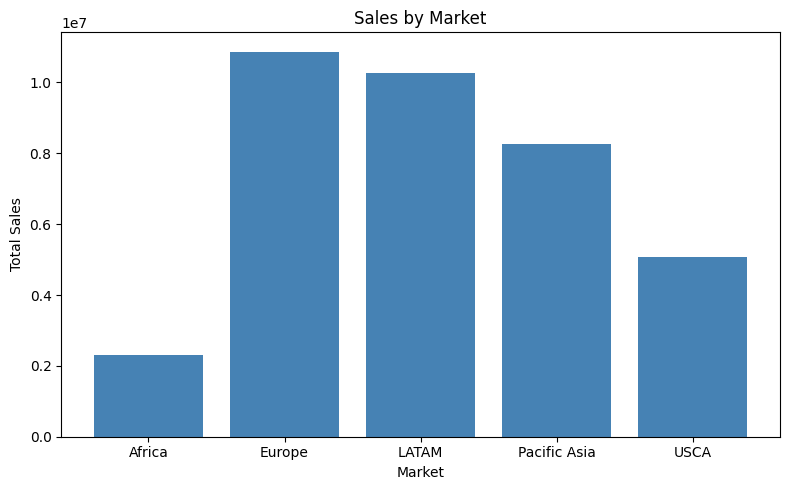

In [33]:
sales_market = df_25.groupby("market")["sales"].sum()

plt.figure(figsize=(8, 5))
plt.bar(sales_market.index, sales_market.values, color="steelblue")
plt.title("Sales by Market")
plt.xlabel("Market")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

Plot name: Horizontal bar plot

Title: Profit by Department (top 8)

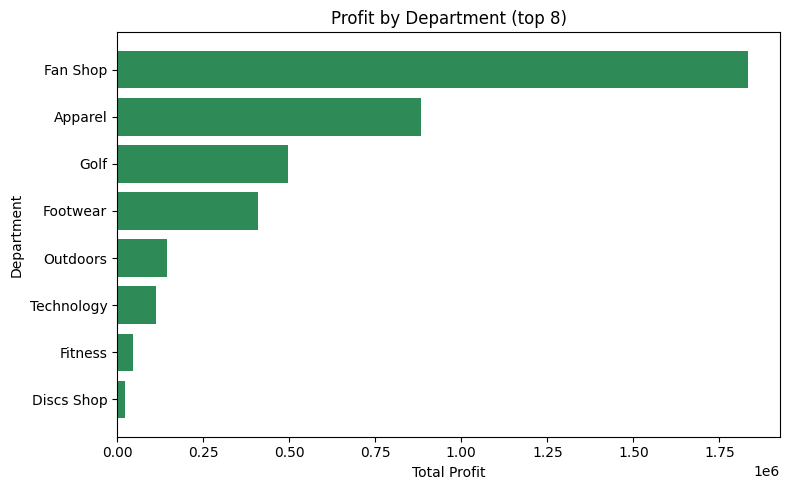

In [34]:
profit_dept = df_25.groupby("department_name")["order_profit"].sum().sort_values().tail(8)

plt.figure(figsize=(8, 5))
plt.barh(profit_dept.index, profit_dept.values, color="seagreen")
plt.title("Profit by Department (top 8)")
plt.xlabel("Total Profit")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

Plot name: Histogram

Title: Actual Shipping Days

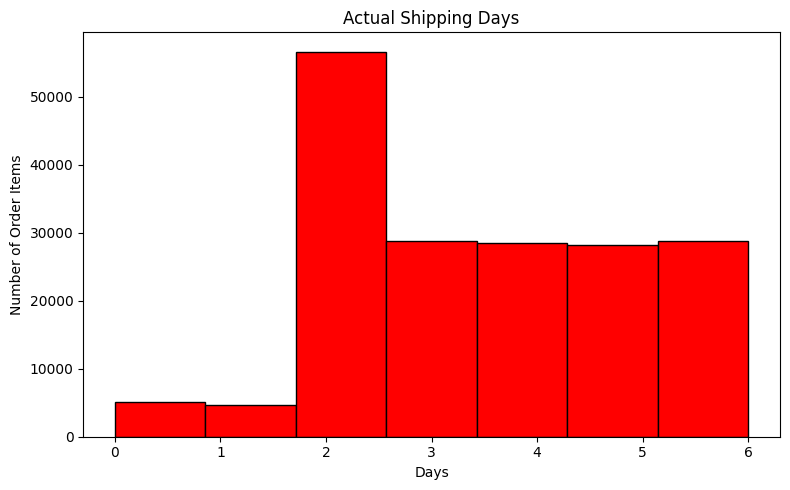

In [35]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_25["actual_shipping_days"],
    bins=7,
    color="Red",
    edgecolor="black"
)

plt.title("Actual Shipping Days")
plt.xlabel("Days")
plt.ylabel("Number of Order Items")

plt.tight_layout()
plt.show()



Plot name: Pie chart

Title: Orders by Customer Segment

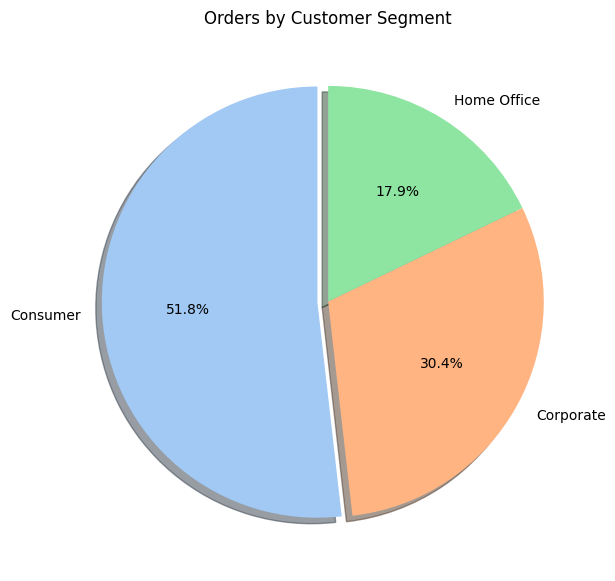

In [36]:
seg = df_25["customer_segment"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(seg.values, labels=seg.index, autopct="%1.1f%%", startangle=90,
       explode=[0.05, 0, 0], shadow=True,
       colors=sns.color_palette("pastel"))
ax.set_title("Orders by Customer Segment")
plt.show()

Plot name: Heatmap (Correlation heatmap)

Title: Correlation Heatmap

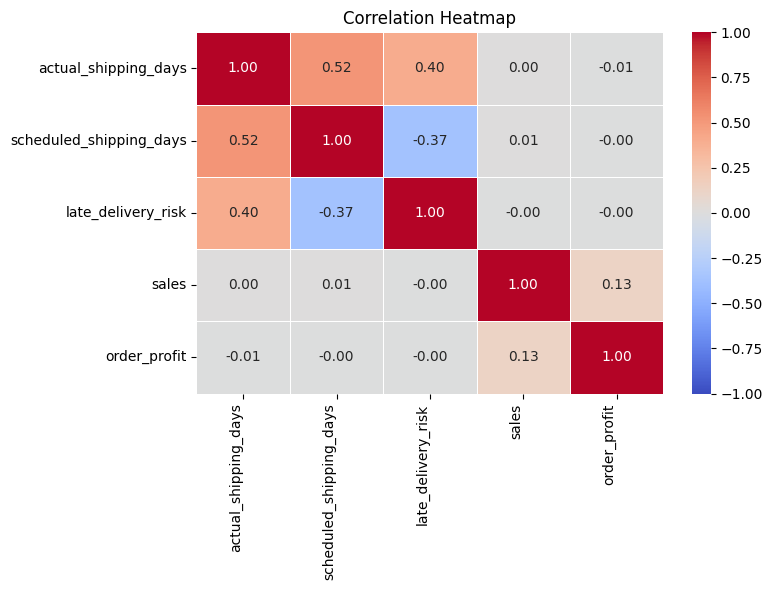

In [37]:
cols = ["actual_shipping_days", "scheduled_shipping_days", "late_delivery_risk", "sales", "order_profit"]

plt.figure(figsize=(8, 6))
sns.heatmap(df_25[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.xticks(rotation=90, ha="right")
plt.tight_layout()
plt.show()

Plot name: Count plot (Grouped bar chart)

Title: Countplot: Delivery Status by Shipping Mode

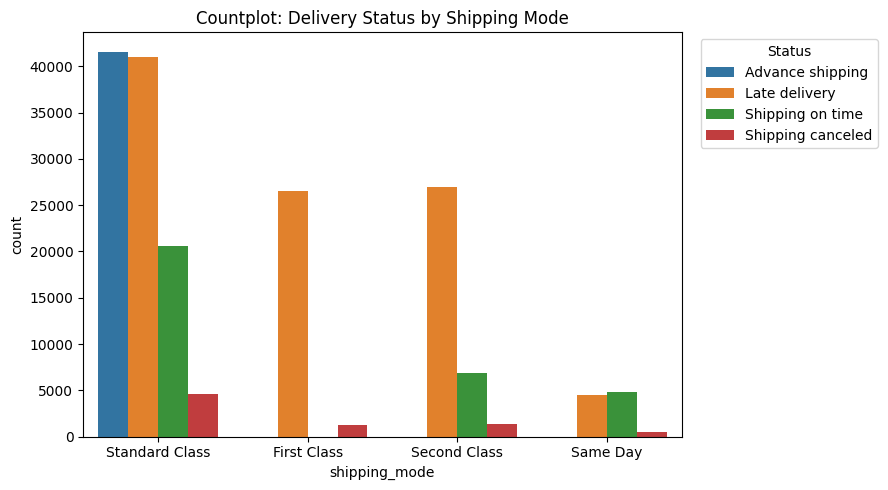

In [38]:

plt.figure(figsize=(9, 5))
sns.countplot(data=df_25, x="shipping_mode", hue="delivery_status")
plt.title("Countplot: Delivery Status by Shipping Mode")
plt.legend(title="Status", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Plot name: Stacked histogram

Title: Shipping Days by Delivery Status

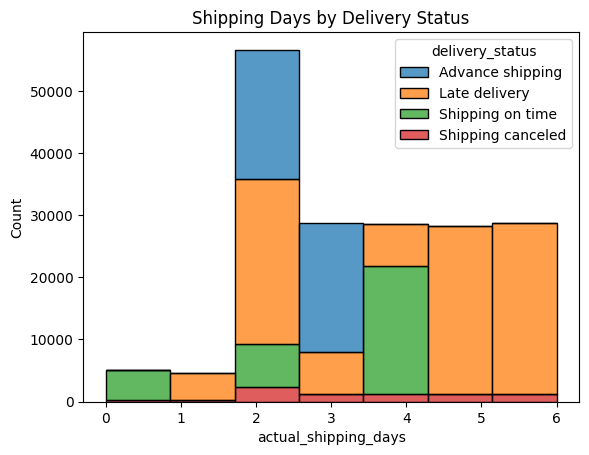

In [39]:
sns.histplot(data=df_25, x="actual_shipping_days", hue="delivery_status", multiple="stack", bins=7)
plt.title("Shipping Days by Delivery Status")
plt.show()

Plot name: Scatter plot with regression line (Regplot)

Title: Sales vs Profit with Trend Line

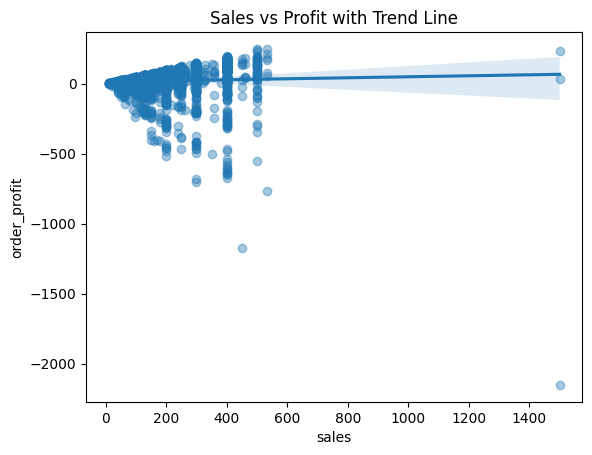

In [42]:
sns.regplot(data=df_25.sample(3000, random_state=1), x="sales", y="order_profit", scatter_kws={"alpha": 0.4})
plt.title("Sales vs Profit with Trend Line")
plt.show()

Plot name: Point plot (line plot with markers)

Title: Average Profit by Year and Segment

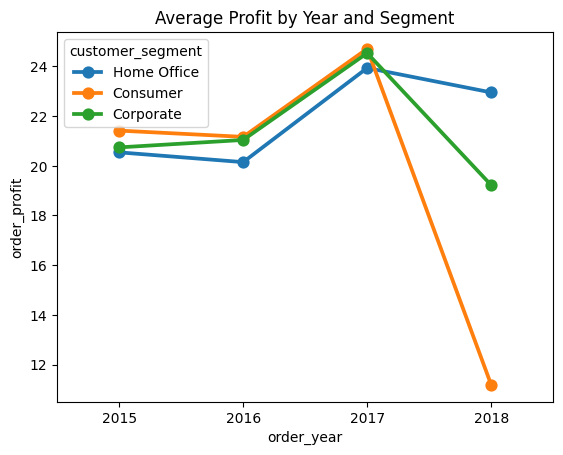

In [43]:
sns.pointplot(data=df_25, x="order_year", y="order_profit", hue="customer_segment", errorbar=None)
plt.title("Average Profit by Year and Segment")
plt.show()

Plot name: Scatter plot

Title: Discount vs Profit

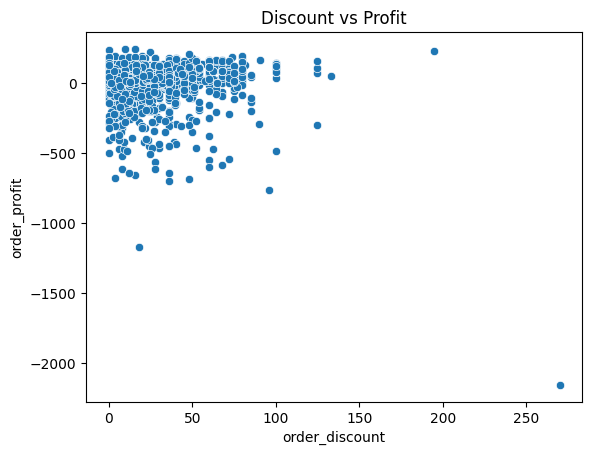

In [44]:
sns.scatterplot(data=df_25.sample(3000, random_state=1), x="order_discount", y="order_profit")
plt.title("Discount vs Profit")
plt.show()